# LightHR fairness audit: the main pipeline

This notebook covers:

1. **Preprocessing**: missing values that mean "unemployed", engineered referee features, a Russell Group flag.
2. **Part A, exploration**: Apriori association rules and K-medoids clustering of rejected applicants.
3. **Part B, classification**: Decision Tree, Bagging, Random Forest, AdaBoost and XGBoost, tuned with 5-fold stratified CV.
4. **Part C, explainability**: SHAP (global) and LIME (local), with a rank-correlation check that they agree.
5. **Part D, fairness**: aif360 group metrics on nine protected splits, intersectional rates, k-NN consistency, counterfactual flips, and Reweighing.

The Russell Group flag here uses exact name matching. `02_follow_up.ipynb` compares it with normalised matching and extends the fairness analysis.

## Setup

`pip install -r requirements.txt`, then put `LightHR_dataset.csv` in `data/` (see `data/README.md`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

CSV_PATH = '../data/LightHR_dataset.csv'
FIG_DIR = '../docs/figures'

## 1. Preprocessing

In [2]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import KBinsDiscretizer, LabelEncoder


# ─────────────────────────────────────────────────────────────────────────────
# 1. Load raw data
# ─────────────────────────────────────────────────────────────────────────────
df = pd.read_csv(CSV_PATH)
print(f"Loaded: {df.shape[0]} rows, {df.shape[1]} columns")

# Fix column name typo for friendlier code
df = df.rename(columns={
    'Refree 1': 'Ref1',
    'Refree 2': 'Ref2',
    'Refree 3': 'Ref3',
    'Age at time of application': 'Age',
    'Year of Application': 'Year',
    'A-levels scores': 'ALevels',
    'Current Annual Income': 'Income',
    'Current Employment': 'Employment',
    'Current Employment Sector': 'EmpSector',
    'References Submitted': 'RefsSubmitted',
    'University Name': 'University',
    'Was Hired by a Company within 6 months': 'Hired',
})

# ─────────────────────────────────────────────────────────────────────────────
# 2. Handle missing values (documented in report)
# ─────────────────────────────────────────────────────────────────────────────
# Employment / EmpSector NaN == "None" (unemployed) per dataset spec
df['Employment'] = df['Employment'].fillna('None')
df['EmpSector'] = df['EmpSector'].fillna('None')

# Refs missing iff RefsSubmitted == 0 (verified earlier). Mark explicitly.
for col in ['Ref1', 'Ref2', 'Ref3']:
    df[col] = df[col].fillna('None:None')

# ─────────────────────────────────────────────────────────────────────────────
# 3. Engineer referee features
# ─────────────────────────────────────────────────────────────────────────────
def split_ref(r):
    """Parse 'Salaried:Health' → ('Salaried','Health')"""
    if r == 'None:None':
        return ('None', 'None')
    parts = r.split(':')
    return (parts[0], parts[1]) if len(parts) == 2 else ('None', 'None')

for i in (1, 2, 3):
    df[[f'Ref{i}_Emp', f'Ref{i}_Sec']] = df[f'Ref{i}'].apply(
        lambda r: pd.Series(split_ref(r))
    )

# Feature 1 — how many referees were actually supplied (0 or 3, given data pattern
# but coded generically so it generalises)
df['Ref_Count'] = (
    (df['Ref1_Emp'] != 'None').astype(int) +
    (df['Ref2_Emp'] != 'None').astype(int) +
    (df['Ref3_Emp'] != 'None').astype(int)
)

# Feature 2 — sector alignment: how many referees share the candidate's sector?
def sector_match(row):
    if row['EmpSector'] == 'None':
        return 0
    return sum(
        row[f'Ref{i}_Sec'] == row['EmpSector'] for i in (1, 2, 3)
    )
df['Ref_Sector_Match'] = df.apply(sector_match, axis=1)

# Feature 3 — diversity of referee sectors (unique sectors among supplied refs)
def sector_diversity(row):
    secs = {row[f'Ref{i}_Sec'] for i in (1, 2, 3) if row[f'Ref{i}_Sec'] != 'None'}
    return len(secs)
df['Ref_Sector_Diversity'] = df.apply(sector_diversity, axis=1)

# Feature 4 — salaried-referee weight (are refs from "established" salaried roles
# rather than contractual/self-business?)
def salaried_refs(row):
    return sum(row[f'Ref{i}_Emp'] == 'Salaried' for i in (1, 2, 3))
df['Ref_Salaried_Count'] = df.apply(salaried_refs, axis=1)

# ─────────────────────────────────────────────────────────────────────────────
# 4. Russell Group flag (proxy check — acknowledged as a proxy in report)
#    Full list of 24 Russell Group universities (UK).
# ─────────────────────────────────────────────────────────────────────────────
russell_group = {
    'UNIVERSITY OF BIRMINGHAM', 'UNIVERSITY OF BRISTOL', 'UNIVERSITY OF CAMBRIDGE',
    'CARDIFF UNIVERSITY', 'DURHAM UNIVERSITY', 'UNIVERSITY OF EDINBURGH',
    'UNIVERSITY OF EXETER', 'UNIVERSITY OF GLASGOW', "IMPERIAL COLLEGE LONDON",
    "KING'S COLLEGE LONDON", 'UNIVERSITY OF LEEDS', 'UNIVERSITY OF LIVERPOOL',
    'LONDON SCHOOL OF ECONOMICS AND POLITICAL SCIENCE', 'UNIVERSITY OF MANCHESTER',
    'NEWCASTLE UNIVERSITY', 'UNIVERSITY OF NOTTINGHAM', 'UNIVERSITY OF OXFORD',
    'QUEEN MARY UNIVERSITY OF LONDON', "QUEEN'S UNIVERSITY BELFAST",
    'UNIVERSITY OF SHEFFIELD', 'UNIVERSITY OF SOUTHAMPTON',
    'UNIVERSITY COLLEGE LONDON', 'UNIVERSITY OF WARWICK', 'UNIVERSITY OF YORK'
}
# Exact matching on upper-cased names. 02_follow_up.ipynb compares this with
# normalised matching (lighthr.universities.is_russell_group).
df['Russell_Group'] = df['University'].str.upper().isin(russell_group).astype(int)
print(f"Russell Group hit rate in dataset: {df['Russell_Group'].mean():.3f}")

# ─────────────────────────────────────────────────────────────────────────────
# 5. Build df_arm — one-hot boolean frame for Apriori (mlxtend expects bool)
# ─────────────────────────────────────────────────────────────────────────────
# Discretise continuous variables into interpretable bins for ARM
df_arm_src = df.copy()

# Age: 40-49 → 3 bins (younger/mid/older within this narrow range)
df_arm_src['AgeBin'] = pd.cut(df_arm_src['Age'], bins=[39, 43, 46, 49],
                               labels=['Age_40-43', 'Age_44-46', 'Age_47-49'])
# Year: pre-2008, 2008-2019 (stable), 2020-21 COVID, 2022+ post-COVID
df_arm_src['YearBin'] = pd.cut(df_arm_src['Year'], bins=[1997, 2007, 2019, 2021, 2023],
                                labels=['Year_1998-2007', 'Year_2008-2019',
                                        'Year_2020-2021_COVID', 'Year_2022+'])
# A-levels: low/mid/high
df_arm_src['ALevelsBin'] = pd.cut(df_arm_src['ALevels'], bins=[39, 55, 70, 90],
                                   labels=['ALevels_Low', 'ALevels_Mid', 'ALevels_High'])
# Income: 0 (unemployed), low, mid, high
def inc_bin(x):
    if x == 0: return 'Income_0'
    if x < 50000: return 'Income_Low'
    if x < 100000: return 'Income_Mid'
    return 'Income_High'
df_arm_src['IncomeBin'] = df_arm_src['Income'].apply(inc_bin)

# Columns we'll feed to Apriori (mix of binned continuous + categorical)
arm_cols = ['Gender', 'Education', 'Employment', 'EmpSector',
            'AgeBin', 'YearBin', 'ALevelsBin', 'IncomeBin']
# Hired as a label-like attribute in ARM
df_arm_src['HiredLabel'] = df_arm_src['Hired'].map({0: 'Hired_No', 1: 'Hired_Yes'})
arm_cols.append('HiredLabel')

# One-hot encode everything as boolean
df_arm = pd.get_dummies(df_arm_src[arm_cols], prefix='', prefix_sep='')
# Convert to bool dtype (mlxtend 0.22+ prefers bool over int to silence warnings)
df_arm = df_arm.astype(bool)

print(f"df_arm shape: {df_arm.shape} (one-hot boolean for Apriori)")

# ─────────────────────────────────────────────────────────────────────────────
# 6. Build df_cls — classification / fairness / XAI frame
# ─────────────────────────────────────────────────────────────────────────────
df_cls = df.copy()

# Drop raw reference strings (we have engineered features now)
cls_drop = ['Ref1', 'Ref2', 'Ref3', 'Ref1_Emp', 'Ref2_Emp', 'Ref3_Emp',
            'Ref1_Sec', 'Ref2_Sec', 'Ref3_Sec', 'University']  # drop raw univ, keep Russell_Group
df_cls = df_cls.drop(columns=cls_drop)

# Label-encode low-cardinality categoricals
label_encoders = {}
for col in ['Gender', 'Education', 'Employment', 'EmpSector', 'Address']:
    le = LabelEncoder()
    df_cls[col] = le.fit_transform(df_cls[col].astype(str))
    label_encoders[col] = le

# Keep a human-readable mapping so we can interpret feature importances
gender_map = dict(zip(label_encoders['Gender'].classes_,
                      label_encoders['Gender'].transform(label_encoders['Gender'].classes_)))
print("Gender encoding:", gender_map)

print(f"df_cls shape: {df_cls.shape}")
print(f"df_cls columns: {list(df_cls.columns)}")
print(f"Class balance: {df_cls['Hired'].value_counts().to_dict()}")

# ─────────────────────────────────────────────────────────────────────────────
# 7. Save all outputs
# ─────────────────────────────────────────────────────────────────────────────

# ─────────────────────────────────────────────────────────────────────────────
# 8. Make outputs available to subsequent cells (in lieu of pickle round-trip)
# ─────────────────────────────────────────────────────────────────────────────
data = {'df_arm': df_arm, 'df_cls': df_cls, 'df_raw': df}
pp   = {'df_cls': df_cls, 'gender_map': gender_map, 'df_raw': df,
        'label_encoders': label_encoders}
print("\nIn-memory dicts ready: data, pp")


Loaded: 8800 rows, 15 columns


Russell Group hit rate in dataset: 0.153
df_arm shape: (8800, 36) (one-hot boolean for Apriori)
Gender encoding: {'Female': 0, 'Male': 1, 'Non-binary': 2, 'Trans': 3}
df_cls shape: (8800, 16)
df_cls columns: ['Gender', 'Age', 'Year', 'ALevels', 'Education', 'Address', 'Employment', 'EmpSector', 'Income', 'RefsSubmitted', 'Hired', 'Ref_Count', 'Ref_Sector_Match', 'Ref_Sector_Diversity', 'Ref_Salaried_Count', 'Russell_Group']
Class balance: {0: 6690, 1: 2110}

In-memory dicts ready: data, pp


## 2. Part A — Exploration (K-medoids + Apriori)

══════════════════════════════════════════════════════════════════════
1. GLOBAL APRIORI
══════════════════════════════════════════════════════════════════════


Frequent itemsets found: 665
By length: {1: 36, 2: 313, 3: 287, 4: 29}

Rules with Hired_* consequent: 281

Top 10 rules → Hired_Yes:
  Salaried, ALevels_High                                  → Hired_Yes  (sup=0.080 conf=0.712 lift=2.97)
  Self Business, ALevels_High                             → Hired_Yes  (sup=0.078 conf=0.702 lift=2.93)
  Contractual, ALevels_High                               → Hired_Yes  (sup=0.078 conf=0.696 lift=2.90)
  Male, ALevels_High                                      → Hired_Yes  (sup=0.061 conf=0.649 lift=2.71)
  Business, ALevels_High                                  → Hired_Yes  (sup=0.064 conf=0.630 lift=2.63)
  Age_44-46, ALevels_High                                 → Hired_Yes  (sup=0.073 conf=0.626 lift=2.61)
  Income_High, ALevels_High                               → Hired_Yes  (sup=0.086 conf=0.623 lift=2.60)
  Income_Mid, ALevels_High                                → Hired_Yes  (sup=0.081 conf=0.616 lift=2.57)
  Arts, ALevels_High              

  k=3: inertia=1028.50, silhouette=0.1270
  k=4: inertia=982.38, silhouette=0.1192
  k=5: inertia=943.63, silhouette=0.0574


  k=6: inertia=915.50, silhouette=0.0528
  k=7: inertia=870.62, silhouette=0.0571


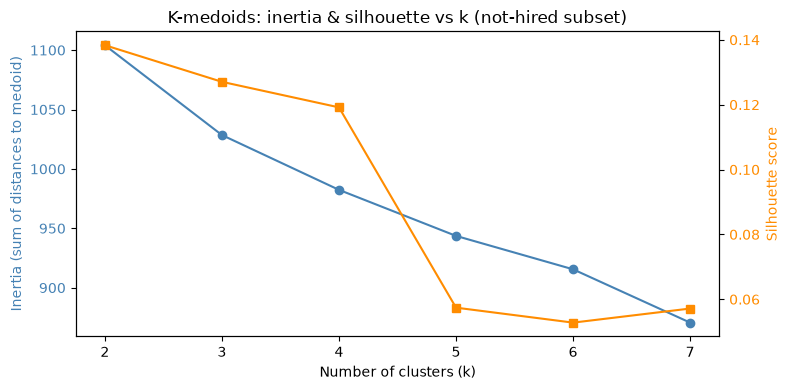

Saved elbow plot

Best k by silhouette: 2
Fitting final K-medoids with k=2 on full not-hired set (n=6690)...



Cluster sizes: {0: 4046, 1: 2644}

Medoid profiles (cluster centres) — top 5 features present:
  Cluster 0 (n=4046): Trans, Law, Contractual, Arts, Age_40-43, Year_2008-2019, ALevels_Low, Income_High
  Cluster 1 (n=2644): Female, Arts, None, None, Age_40-43, Year_2008-2019, ALevels_Low, Income_0

══════════════════════════════════════════════════════════════════════
3. APRIORI WITHIN EACH CLUSTER (cluster-specific patterns)
══════════════════════════════════════════════════════════════════════
  (using min_support = 0.2 for cluster 0)

Cluster 0 (n=4046) — top 5 frequent itemsets:
  Income_High                                                   sup=0.500
  Year_2008-2019                                                sup=0.456
  ALevels_Low                                                   sup=0.428
  Income_Mid                                                    sup=0.419
  Year_1998-2007                                                sup=0.416
  (using min_support = 0.3 for cluster 1)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import pairwise_distances, silhouette_score
from mlxtend.frequent_patterns import apriori, association_rules

# Load preprocessed
df_arm = data['df_arm']
df_raw = data['df_raw']

# ─────────────────────────────────────────────────────────────────────────────
# 1. APRIORI — Global patterns on the full dataset
# ─────────────────────────────────────────────────────────────────────────────
print("═" * 70)
print("1. GLOBAL APRIORI")
print("═" * 70)

# Use min_support = 0.05 (patterns present in ≥5% of records)
# Justification in report: low enough to catch minority-group patterns,
# high enough to keep lattice computationally manageable
MIN_SUPPORT = 0.05
MIN_CONF = 0.30

freq_global = apriori(df_arm, min_support=MIN_SUPPORT, use_colnames=True,
                       max_len=4)
freq_global['length'] = freq_global['itemsets'].apply(len)
print(f"Frequent itemsets found: {len(freq_global)}")
print(f"By length: {freq_global['length'].value_counts().sort_index().to_dict()}")

rules_global = association_rules(freq_global, metric='confidence',
                                  min_threshold=MIN_CONF)
# Filter for lift > 1 (statistical dependence — Week 8 point on confidence
# being misleading, remember the Tea→Coffee example)
rules_global = rules_global[rules_global['lift'] > 1].copy()
# Sort by lift descending
rules_global = rules_global.sort_values('lift', ascending=False)

# Rules whose consequent involves Hired (what we really care about)
def contains_hired(itemset):
    return any('Hired_' in item for item in itemset)

rules_hired = rules_global[rules_global['consequents'].apply(contains_hired)].copy()
print(f"\nRules with Hired_* consequent: {len(rules_hired)}")
print("\nTop 10 rules → Hired_Yes:")
rules_yes = rules_hired[
    rules_hired['consequents'].apply(lambda s: 'Hired_Yes' in s)
].head(10)
for _, r in rules_yes.iterrows():
    ant = ', '.join(r['antecedents'])
    con = ', '.join(r['consequents'])
    print(f"  {ant:<55} → {con}  "
          f"(sup={r['support']:.3f} conf={r['confidence']:.3f} lift={r['lift']:.2f})")

print("\nTop 10 rules → Hired_No:")
rules_no = rules_hired[
    rules_hired['consequents'].apply(lambda s: 'Hired_No' in s)
].head(10)
for _, r in rules_no.iterrows():
    ant = ', '.join(r['antecedents'])
    con = ', '.join(r['consequents'])
    print(f"  {ant:<55} → {con}  "
          f"(sup={r['support']:.3f} conf={r['confidence']:.3f} lift={r['lift']:.2f})")

# ─────────────────────────────────────────────────────────────────────────────
# 2. K-MEDOIDS CLUSTERING on not-hired subset (Lab 10 pattern)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("2. K-MEDOIDS CLUSTERING (not-hired applicants)")
print("═" * 70)

# Why K-medoids not K-means?
#   - Our features are one-hot boolean (high-dimensional categorical).
#   - K-means' Euclidean centroid doesn't map onto a meaningful "typical"
#     profile in one-hot space (means are fractional).
#   - K-medoids picks an actual data point as each cluster centre, which
#     is directly interpretable as a representative candidate profile.

# Focus on failed hires (as Lab 10 programming task instructs)
nothired_mask = df_arm['Hired_No']
X_nothired = df_arm[nothired_mask].drop(columns=['Hired_No', 'Hired_Yes']).reset_index(drop=True)
print(f"Records (not hired): {X_nothired.shape[0]}")

# Cosine distance on one-hot is appropriate here because:
#   - Our feature vectors are sparse binary (exactly 8 True values each)
#   - Euclidean distance on binary data gives identical results for any two
#     rows differing in the same number of positions, losing structure
#   - Cosine captures proportional overlap — directly relates to the Jaccard-style
#     intuition in market-basket data (Week 8)

# Elbow analysis uses a sub-sample for speed (full-dataset fit happens after k is chosen).
# 2000 is large enough for a stable silhouette estimate and keeps PAM tractable.
SAMPLE_N = 2000
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_nothired), size=min(SAMPLE_N, len(X_nothired)), replace=False)
X_sample = X_nothired.iloc[sample_idx].reset_index(drop=True)
print(f"Computing pairwise cosine distance on sample of {len(X_sample)} for elbow search...")
D_sample = pairwise_distances(X_sample.astype(int).to_numpy(), metric='cosine')

print("Running K-medoids for k = 2..7 (elbow search, alternate method for speed)...")
inertias = []
silhouettes = []
k_range = range(2, 8)
for k in k_range:
    km = KMedoids(n_clusters=k, metric='precomputed',
                   method='alternate', init='k-medoids++', random_state=42,
                   max_iter=100)
    labels = km.fit_predict(D_sample)
    inertias.append(km.inertia_)
    sil = silhouette_score(D_sample, labels, metric='precomputed')
    silhouettes.append(sil)
    print(f"  k={k}: inertia={km.inertia_:.2f}, silhouette={sil:.4f}")

# Plot elbow
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(list(k_range), inertias, 'o-', color='steelblue', label='Inertia')
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Inertia (sum of distances to medoid)', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax2 = ax1.twinx()
ax2.plot(list(k_range), silhouettes, 's-', color='darkorange', label='Silhouette')
ax2.set_ylabel('Silhouette score', color='darkorange')
ax2.tick_params(axis='y', labelcolor='darkorange')
plt.title('K-medoids: inertia & silhouette vs k (not-hired subset)')
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_elbow.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved elbow plot")

# Pick best k — highest silhouette in a reasonable range
best_k = list(k_range)[int(np.argmax(silhouettes))]
print(f"\nBest k by silhouette: {best_k}")

# Fit final K-medoids on the full not-hired subset using the chosen k.
# Compute distance matrix in chunks to stay under memory limits isn't needed
# here (6690×6690 ≈ 360 MB at float64) — we just use alternate for speed.
print(f"Fitting final K-medoids with k={best_k} on full not-hired set (n={len(X_nothired)})...")
D_full = pairwise_distances(X_nothired.astype(int).to_numpy(), metric='cosine')
km_final = KMedoids(n_clusters=best_k, metric='precomputed',
                     method='alternate', init='k-medoids++', random_state=42,
                     max_iter=200)
cluster_labels = km_final.fit_predict(D_full)

# Label cluster assignments back onto X_nothired
X_nothired_lab = X_nothired.copy()
X_nothired_lab['Cluster'] = cluster_labels
print(f"\nCluster sizes: {pd.Series(cluster_labels).value_counts().sort_index().to_dict()}")

# Describe each cluster by its medoid profile
medoid_indices = km_final.medoid_indices_
print("\nMedoid profiles (cluster centres) — top 5 features present:")
cluster_profiles = []
for c in range(best_k):
    medoid_row = X_nothired.iloc[medoid_indices[c]]
    top_feats = medoid_row[medoid_row].index.tolist()
    cluster_profiles.append({'cluster': c, 'size': int((cluster_labels == c).sum()),
                             'medoid_features': top_feats})
    print(f"  Cluster {c} (n={int((cluster_labels == c).sum())}): "
          f"{', '.join(top_feats[:8])}")

# ─────────────────────────────────────────────────────────────────────────────
# 3. APRIORI WITHIN EACH CLUSTER
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("3. APRIORI WITHIN EACH CLUSTER (cluster-specific patterns)")
print("═" * 70)

cluster_rules = {}
for c in range(best_k):
    mask = (cluster_labels == c)
    df_c = X_nothired[mask]
    if len(df_c) < 50:
        print(f"\nCluster {c} too small (n={len(df_c)}), skipping Apriori")
        continue
    # Cluster 0 (employed-but-rejected) is more heterogeneous, so use 0.20 to
    # surface dominant patterns that don't reach 0.30 support. Cluster 1 (unemployed)
    # is highly homogeneous, so 0.30 keeps the itemset list focused.
    cluster_min_sup = 0.20 if c == 0 else 0.30
    fi_c = apriori(df_c, min_support=cluster_min_sup, use_colnames=True, max_len=3)
    print(f"  (using min_support = {cluster_min_sup} for cluster {c})")
    if len(fi_c) > 0:
        # Rank by support so we see the dominant profile
        fi_c = fi_c.sort_values('support', ascending=False)
        print(f"\nCluster {c} (n={mask.sum()}) — top 5 frequent itemsets:")
        for _, row in fi_c.head(5).iterrows():
            print(f"  {', '.join(row['itemsets']):<60}  sup={row['support']:.3f}")
    cluster_rules[c] = fi_c

# ─────────────────────────────────────────────────────────────────────────────
# 4. GENDER × HIRED CROSS-TABULATION (Part A/D linkage preview)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("4. KEY DEMOGRAPHIC CROSS-TABS (for reporting)")
print("═" * 70)

crosstab_gender = pd.crosstab(df_raw['Gender'], df_raw['Hired'], normalize='index')
print("\nHire rate by Gender:")
print(crosstab_gender)

crosstab_edu = pd.crosstab(df_raw['Education'], df_raw['Hired'], normalize='index')
print("\nHire rate by Education:")
print(crosstab_edu)

crosstab_year = pd.crosstab(
    pd.cut(df_raw['Year'], bins=[1997, 2007, 2019, 2021, 2023],
           labels=['1998-2007', '2008-2019', '2020-2021 (COVID)', '2022+']),
    df_raw['Hired'], normalize='index')
print("\nHire rate by Year band:")
print(crosstab_year)

crosstab_rg = pd.crosstab(df_raw['Russell_Group'], df_raw['Hired'], normalize='index')
print("\nHire rate by Russell Group:")
print(crosstab_rg)

# Save Part A outputs


## 3. Part B — Classification

Train: 7040 (0.240 hire rate)
Test : 1760 (0.240 hire rate)
Features: ['Gender', 'Age', 'Year', 'ALevels', 'Education', 'Address', 'Employment', 'EmpSector', 'Income', 'RefsSubmitted', 'Ref_Count', 'Ref_Sector_Match', 'Ref_Sector_Diversity', 'Ref_Salaried_Count', 'Russell_Group']

────────────────────────────────────────────────────────────
Training DecisionTree...
────────────────────────────────────────────────────────────


Best params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 10}
CV accuracy : 0.9625 ± 0.0063
CV error    : 0.0375
CV F1-w     : 0.9630 ± 0.0062
Test accuracy: 0.9665
Test F1 (weighted): 0.9668
Test precision (hired=1): 0.9079
Test recall (hired=1): 0.9573
Test F1 (hired=1): 0.9319

────────────────────────────────────────────────────────────
Training Bagging...
────────────────────────────────────────────────────────────


Best params: {'max_samples': 0.7, 'n_estimators': 100}
CV accuracy : 0.9690 ± 0.0040
CV error    : 0.0310
CV F1-w     : 0.9688 ± 0.0041
Test accuracy: 0.9722
Test F1 (weighted): 0.9721
Test precision (hired=1): 0.9494
Test recall (hired=1): 0.9336
Test F1 (hired=1): 0.9415

────────────────────────────────────────────────────────────
Training RandomForest...
────────────────────────────────────────────────────────────


Best params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
CV accuracy : 0.9669 ± 0.0056
CV error    : 0.0331
CV F1-w     : 0.9668 ± 0.0057
Test accuracy: 0.9693
Test F1 (weighted): 0.9693
Test precision (hired=1): 0.9381
Test recall (hired=1): 0.9336
Test F1 (hired=1): 0.9359

────────────────────────────────────────────────────────────
Training AdaBoost...
────────────────────────────────────────────────────────────


Best params: {'learning_rate': 1.0, 'n_estimators': 200}
CV accuracy : 0.9696 ± 0.0047
CV error    : 0.0304
CV F1-w     : 0.9695 ± 0.0048
Test accuracy: 0.9761
Test F1 (weighted): 0.9761
Test precision (hired=1): 0.9567
Test recall (hired=1): 0.9431
Test F1 (hired=1): 0.9499

────────────────────────────────────────────────────────────
Training XGBoost...
────────────────────────────────────────────────────────────


Best params: {'learning_rate': 0.3, 'max_depth': 3, 'n_estimators': 200}
CV accuracy : 0.9689 ± 0.0036
CV error    : 0.0311
CV F1-w     : 0.9689 ± 0.0036
Test accuracy: 0.9699
Test F1 (weighted): 0.9701
Test precision (hired=1): 0.9165
Test recall (hired=1): 0.9621
Test F1 (hired=1): 0.9387

══════════════════════════════════════════════════════════════════════
MODEL COMPARISON
══════════════════════════════════════════════════════════════════════
       Model  CV Accuracy   CV Std  CV Error  CV F1 (weighted)  Test Accuracy  Test F1 (weighted)  Test Precision (hired=1)  Test Recall (hired=1)  Test F1 (hired=1)
DecisionTree     0.962500 0.006279  0.037500          0.963011       0.966477            0.966777                  0.907865               0.957346           0.931949
     Bagging     0.969034 0.004008  0.030966          0.968827       0.972159            0.972079                  0.949398               0.933649           0.941458
RandomForest     0.966903 0.005585  0.033097      

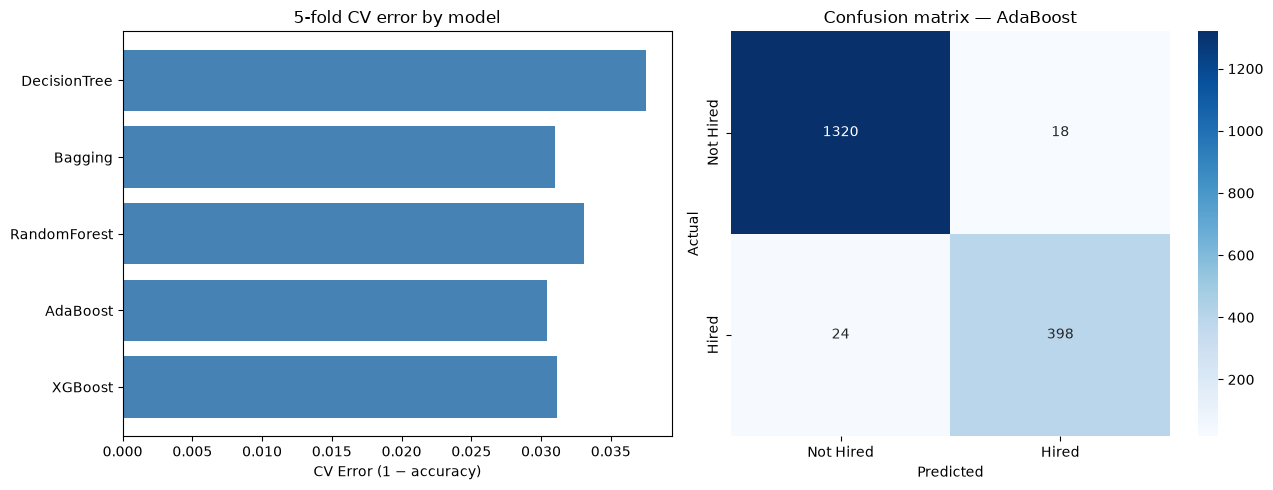


══════════════════════════════════════════════════════════════════════
MODEL DIAGNOSTICS — ROC, PR, Learning curve
══════════════════════════════════════════════════════════════════════
ROC AUC            : 0.9979
Average precision  : 0.9937


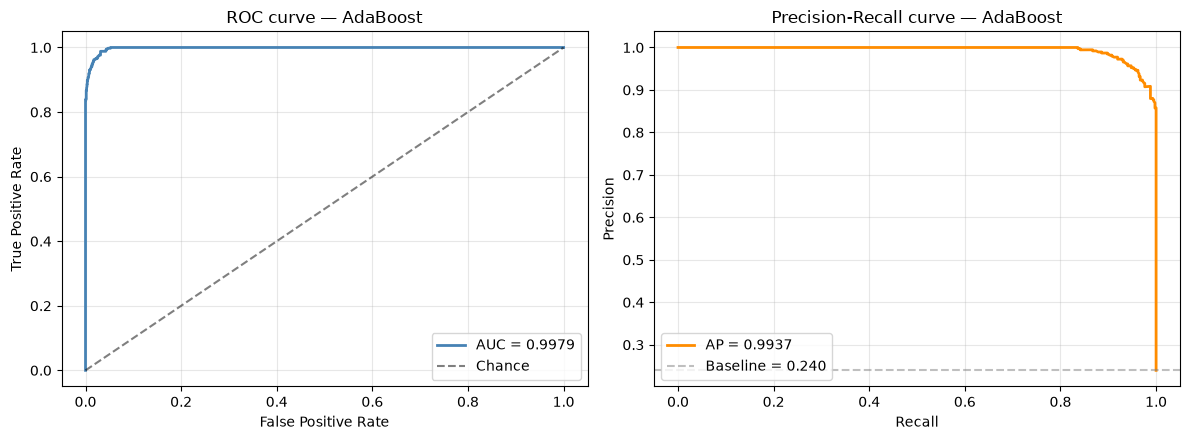

Saved → docs/figures/fig_roc_pr.png

Computing learning curve (5-fold CV across training-set sizes)...


Train-to-CV gap at full training size: 0.0057


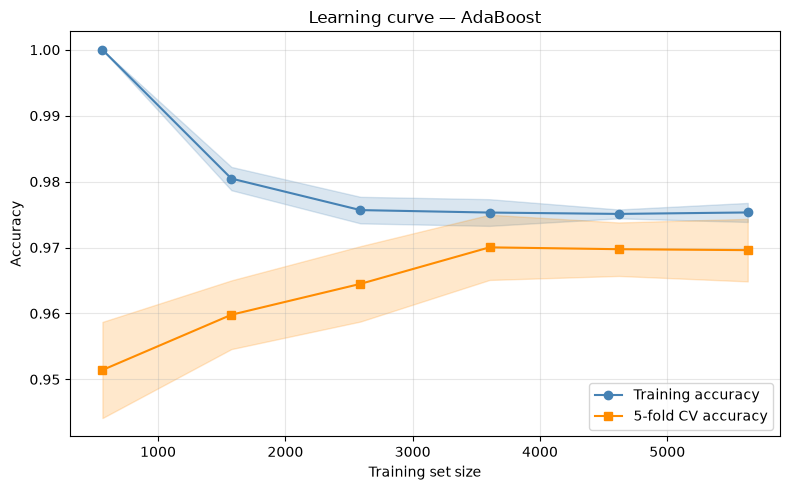

Saved → docs/figures/fig_learning_curve.png


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              ConfusionMatrixDisplay,
                              roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.model_selection import learning_curve
from xgboost import XGBClassifier

# Load preprocessed data
df_cls = data['df_cls']

# ─────────────────────────────────────────────────────────────────────────────
# Train/test split
# ─────────────────────────────────────────────────────────────────────────────
X = df_cls.drop(columns=['Hired'])
y = df_cls['Hired']

# Stratified split preserves the 24% hire rate in both folds
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} ({y_train.mean():.3f} hire rate)")
print(f"Test : {X_test.shape[0]} ({y_test.mean():.3f} hire rate)")
print(f"Features: {list(X.columns)}")

# 5-fold stratified CV — matches Week 3-4 teaching on K-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# F1-weighted chosen as primary CV metric rather than accuracy:
#   • Class imbalance (24% positive) means accuracy can be misleading
#     (Week 3-4 slide 22: "predict all No gives 99% accuracy but misses
#      every positive case")
#   • F1 balances precision and recall — important for hiring where both
#     false positives (wasted interview time) and false negatives
#     (missed good candidates) have costs
SCORING = 'f1_weighted'

# ─────────────────────────────────────────────────────────────────────────────
# Model configurations with hyperparameter grids
# ─────────────────────────────────────────────────────────────────────────────
# Grids kept small (3-4 values per hyperparameter) so GridSearchCV finishes in
# reasonable time. Ranges chosen based on typical recommendations:
#   - max_depth: shallow to deep (3,5,8,None) — covers underfit→overfit spectrum
#   - n_estimators: 50,100,200 — ensemble size tradeoff (more = stable but slow)
#   - learning_rate for boosting: 0.05,0.1,0.3 — standard range
configs = {
    'DecisionTree': {
        'estimator': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
        'grid': {
            'max_depth': [3, 5, 8, None],
            'min_samples_leaf': [1, 10, 50],
            'criterion': ['gini', 'entropy'],
        },
    },
    'Bagging': {
        'estimator': BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=42),
            random_state=42, n_jobs=-1),
        'grid': {
            'n_estimators': [50, 100, 200],
            'max_samples': [0.7, 1.0],
        },
    },
    'RandomForest': {
        'estimator': RandomForestClassifier(random_state=42, n_jobs=-1,
                                             class_weight='balanced'),
        'grid': {
            'n_estimators': [100, 200],
            'max_depth': [5, 10, None],
            'min_samples_leaf': [1, 5],
        },
    },
    'AdaBoost': {
        'estimator': AdaBoostClassifier(random_state=42),
        'grid': {
            'n_estimators': [50, 100, 200],
            'learning_rate': [0.1, 0.5, 1.0],
        },
    },
    'XGBoost': {
        'estimator': XGBClassifier(
            random_state=42, eval_metric='logloss', n_jobs=-1,
            # Handles imbalance similarly to class_weight='balanced'
            scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
        ),
        'grid': {
            'n_estimators': [100, 200],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.05, 0.1, 0.3],
        },
    },
}

# ─────────────────────────────────────────────────────────────────────────────
# Train each model with GridSearchCV + report CV scores
# ─────────────────────────────────────────────────────────────────────────────
results = []
best_models = {}
cv_results_all = {}

for name, cfg in configs.items():
    print("\n" + "─" * 60)
    print(f"Training {name}...")
    print("─" * 60)

    grid = GridSearchCV(
        cfg['estimator'], cfg['grid'],
        cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=True,
    )
    grid.fit(X_train, y_train)
    best = grid.best_estimator_
    best_models[name] = best
    cv_results_all[name] = grid.cv_results_

    # CV error (= 1 - CV accuracy)
    cv_acc_scores = cross_val_score(best, X_train, y_train, cv=cv,
                                     scoring='accuracy', n_jobs=-1)
    cv_f1_scores = cross_val_score(best, X_train, y_train, cv=cv,
                                    scoring='f1_weighted', n_jobs=-1)
    cv_acc_mean, cv_acc_std = cv_acc_scores.mean(), cv_acc_scores.std()
    cv_err = 1 - cv_acc_mean

    # Test-set evaluation
    y_pred = best.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred, average='weighted')
    test_prec = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    test_rec = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    test_f1_pos = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    print(f"Best params: {grid.best_params_}")
    print(f"CV accuracy : {cv_acc_mean:.4f} ± {cv_acc_std:.4f}")
    print(f"CV error    : {cv_err:.4f}")
    print(f"CV F1-w     : {cv_f1_scores.mean():.4f} ± {cv_f1_scores.std():.4f}")
    print(f"Test accuracy: {test_acc:.4f}")
    print(f"Test F1 (weighted): {test_f1:.4f}")
    print(f"Test precision (hired=1): {test_prec:.4f}")
    print(f"Test recall (hired=1): {test_rec:.4f}")
    print(f"Test F1 (hired=1): {test_f1_pos:.4f}")

    results.append({
        'Model': name,
        'CV Accuracy': cv_acc_mean,
        'CV Std': cv_acc_std,
        'CV Error': cv_err,
        'CV F1 (weighted)': cv_f1_scores.mean(),
        'Test Accuracy': test_acc,
        'Test F1 (weighted)': test_f1,
        'Test Precision (hired=1)': test_prec,
        'Test Recall (hired=1)': test_rec,
        'Test F1 (hired=1)': test_f1_pos,
        'Best Params': grid.best_params_,
    })

# ─────────────────────────────────────────────────────────────────────────────
# Results summary + pick best model
# ─────────────────────────────────────────────────────────────────────────────
results_df = pd.DataFrame(results)
print("\n" + "═" * 70)
print("MODEL COMPARISON")
print("═" * 70)
print(results_df.drop(columns=['Best Params']).to_string(index=False))

# Pick the final model on CV accuracy, so the test set plays no part in the choice.
best_idx = results_df['CV Accuracy'].idxmax()
best_name = results_df.loc[best_idx, 'Model']
best_model = best_models[best_name]
print(f"\nBest model: {best_name}")

# Confusion matrix for best model
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
print(f"\nConfusion matrix ({best_name}):")
print(pd.DataFrame(cm,
                    index=['Actual Not Hired', 'Actual Hired'],
                    columns=['Pred Not Hired', 'Pred Hired']))
print(f"\nClassification report ({best_name}):")
print(classification_report(y_test, y_pred_best,
                             target_names=['Not Hired', 'Hired']))

# Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# 1. CV error comparison bar chart
axes[0].barh(results_df['Model'], results_df['CV Error'], color='steelblue')
axes[0].set_xlabel('CV Error (1 − accuracy)')
axes[0].set_title('5-fold CV error by model')
axes[0].invert_yaxis()
# 2. Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Hired', 'Hired'],
            yticklabels=['Not Hired', 'Hired'], ax=axes[1])
axes[1].set_title(f'Confusion matrix — {best_name}')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_classifier_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# Diagnostics — ROC, Precision-Recall, Learning curve for the chosen model
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("MODEL DIAGNOSTICS — ROC, PR, Learning curve")
print("═" * 70)

y_proba = best_model.predict_proba(X_test)[:, 1]

# ROC + PR
fpr, tpr, _   = roc_curve(y_test, y_proba)
roc_auc       = auc(fpr, tpr)
prec, rec, _  = precision_recall_curve(y_test, y_proba)
avg_prec      = average_precision_score(y_test, y_proba)
print(f"ROC AUC            : {roc_auc:.4f}")
print(f"Average precision  : {avg_prec:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, linewidth=2, color='steelblue', label=f'AUC = {roc_auc:.4f}')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Chance')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title(f'ROC curve — {best_name}')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec, linewidth=2, color='darkorange', label=f'AP = {avg_prec:.4f}')
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', alpha=0.5,
                 label=f'Baseline = {y_test.mean():.3f}')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title(f'Precision-Recall curve — {best_name}')
axes[1].legend(loc='lower left')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_roc_pr.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved → docs/figures/fig_roc_pr.png")

# Learning curve
print("\nComputing learning curve (5-fold CV across training-set sizes)...")
train_sizes = np.linspace(0.1, 1.0, 6)
ls_sizes, ls_train, ls_val = learning_curve(
    best_model, X_train, y_train, cv=cv, n_jobs=-1,
    train_sizes=train_sizes, scoring='accuracy', random_state=42
)
ls_train_mean, ls_train_std = ls_train.mean(axis=1), ls_train.std(axis=1)
ls_val_mean,   ls_val_std   = ls_val.mean(axis=1),   ls_val.std(axis=1)
final_gap = ls_train_mean[-1] - ls_val_mean[-1]
print(f"Train-to-CV gap at full training size: {final_gap:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(ls_sizes, ls_train_mean, 'o-', color='steelblue', label='Training accuracy')
plt.fill_between(ls_sizes, ls_train_mean - ls_train_std, ls_train_mean + ls_train_std,
                 alpha=0.2, color='steelblue')
plt.plot(ls_sizes, ls_val_mean, 's-', color='darkorange', label='5-fold CV accuracy')
plt.fill_between(ls_sizes, ls_val_mean - ls_val_std, ls_val_mean + ls_val_std,
                 alpha=0.2, color='darkorange')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title(f'Learning curve — {best_name}')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_learning_curve.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved → docs/figures/fig_learning_curve.png")

# ─────────────────────────────────────────────────────────────────────────────
# Publish results to subsequent cells (in lieu of pickle round-trip)
# ─────────────────────────────────────────────────────────────────────────────
b = {
    'best_models': best_models, 'best_name': best_name,
    'X_train': X_train, 'X_test': X_test,
    'y_train': y_train, 'y_test': y_test,
    'y_pred_best': y_pred_best, 'y_proba': y_proba,
    'results_df': results_df,
    'roc_auc': roc_auc, 'avg_precision': avg_prec,
    'learning_curve': {'sizes': ls_sizes,
                        'train_mean': ls_train_mean, 'val_mean': ls_val_mean},
}
# Save everything


## 4. Part C — SHAP + LIME

Best model: AdaBoost
Features: ['Gender', 'Age', 'Year', 'ALevels', 'Education', 'Address', 'Employment', 'EmpSector', 'Income', 'RefsSubmitted', 'Ref_Count', 'Ref_Sector_Match', 'Ref_Sector_Diversity', 'Ref_Salaried_Count', 'Russell_Group']

══════════════════════════════════════════════════════════════════════
SHAP ANALYSIS
══════════════════════════════════════════════════════════════════════
Background sample: 30  |  Explain sample: 150
Computing SHAP values via KernelExplainer (this can take a few minutes)...


  0%|          | 0/150 [00:00<?, ?it/s]

SHAP values shape: (150, 15)

SHAP global feature importance (top 10):
             feature  mean_abs_shap
             ALevels       0.130016
       RefsSubmitted       0.027360
           EmpSector       0.025551
Ref_Sector_Diversity       0.014387
           Ref_Count       0.011948
  Ref_Salaried_Count       0.006834
              Income       0.006630
             Address       0.002498
              Gender       0.002174
       Russell_Group       0.001865


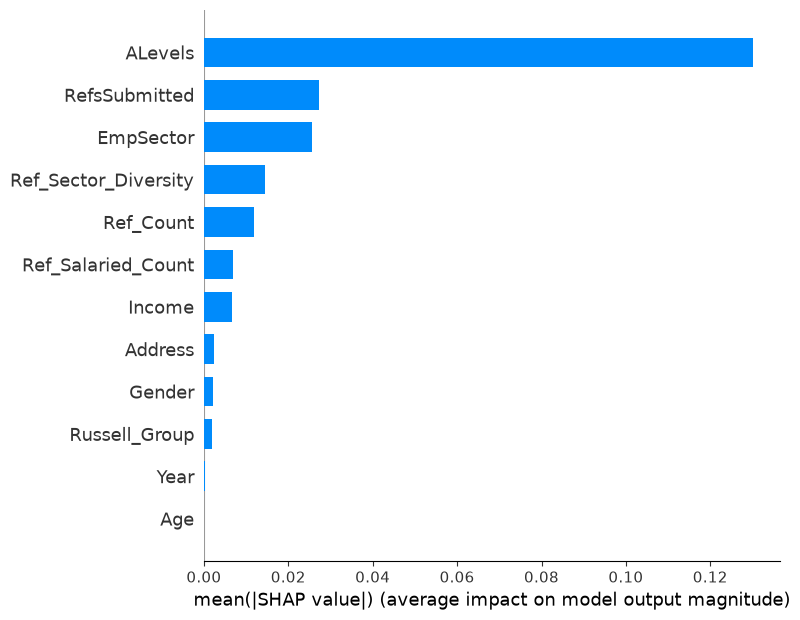

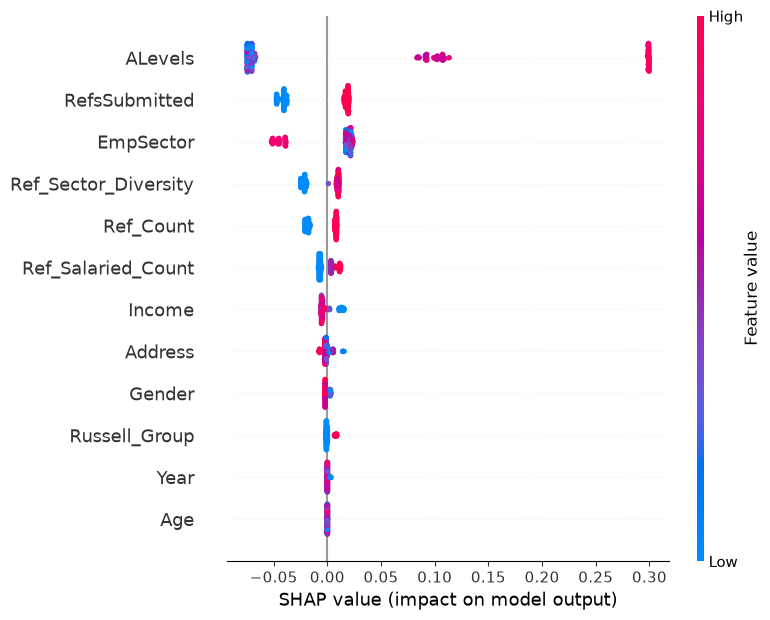

Saved SHAP bar & beeswarm plots

Generating SHAP dependence plots for top 2 features...


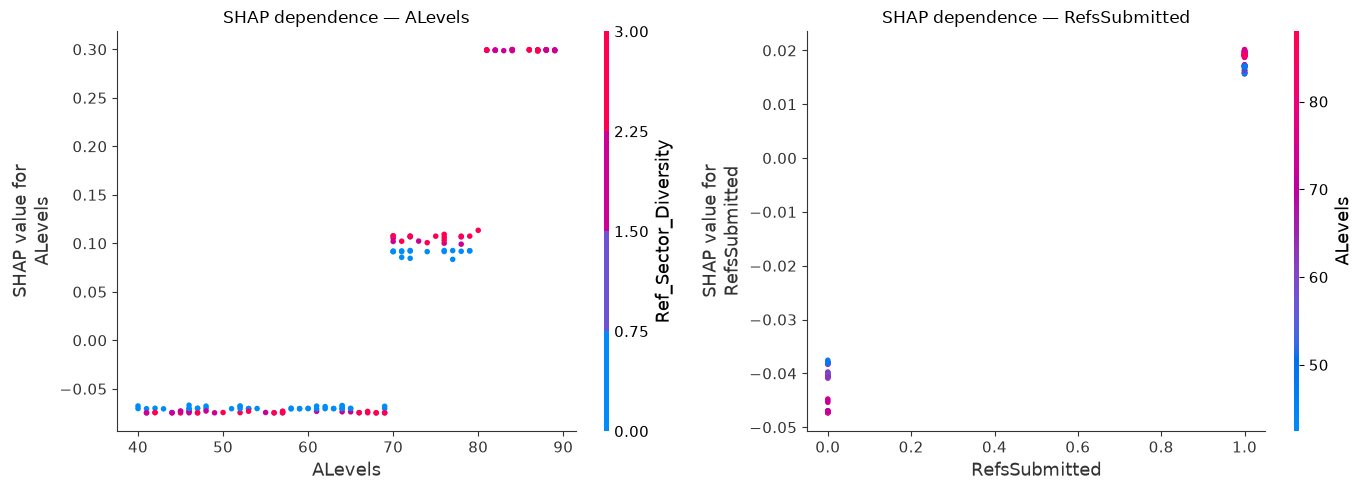

Saved SHAP dependence plots for ['ALevels', 'RefsSubmitted']

══════════════════════════════════════════════════════════════════════
LIME ANALYSIS
══════════════════════════════════════════════════════════════════════

Record 1095  (true=0, pred=0, P(hired)=0.150):
  52.00 < ALevels <= 65.00                  weight=-0.152  [↓ hired]
  EmpSector=6                               weight=-0.072  [↓ hired]
  RefsSubmitted=0                           weight=-0.066  [↓ hired]
  Ref_Sector_Diversity <= 0.00              weight=-0.035  [↓ hired]
  Income <= 0.00                            weight=+0.023  [↑ hired]

Record 1573  (true=0, pred=0, P(hired)=0.187):
  ALevels <= 52.00                          weight=-0.155  [↓ hired]
  RefsSubmitted=0                           weight=-0.066  [↓ hired]
  Ref_Count <= 0.00                         weight=-0.043  [↓ hired]
  0.00 < Income <= 76460.50                 weight=-0.032  [↓ hired]
  Ref_Sector_Diversity <= 0.00              weight=-0.026  [↓ hir


Record 1362  (true=1, pred=1, P(hired)=0.679):
  ALevels > 78.00                           weight=+0.296  [↑ hired]
  RefsSubmitted=1                           weight=+0.062  [↑ hired]
  0.00 < Ref_Count <= 3.00                  weight=+0.027  [↑ hired]
  Ref_Salaried_Count <= 0.00                weight=-0.017  [↓ hired]
  EmpSector=3                               weight=+0.016  [↑ hired]

Record 1464  (true=0, pred=0, P(hired)=0.495):
  ALevels > 78.00                           weight=+0.299  [↑ hired]
  RefsSubmitted=1                           weight=+0.069  [↑ hired]
  0.00 < Ref_Count <= 3.00                  weight=+0.028  [↑ hired]
  0.00 < Ref_Sector_Diversity <= 2.00       weight=+0.016  [↑ hired]
  76460.50 < Income <= 113589.75            weight=-0.012  [↓ hired]

Record 1014  (true=1, pred=1, P(hired)=0.688):
  ALevels > 78.00                           weight=+0.304  [↑ hired]
  RefsSubmitted=1                           weight=+0.072  [↑ hired]
  0.00 < Ref_Count <= 3.00  


Record 528  (true=0, pred=0, P(hired)=0.150):
  ALevels <= 52.00                          weight=-0.153  [↓ hired]
  EmpSector=6                               weight=-0.085  [↓ hired]
  RefsSubmitted=0                           weight=-0.065  [↓ hired]
  Income <= 0.00                            weight=+0.031  [↑ hired]
  Ref_Count <= 0.00                         weight=-0.029  [↓ hired]

Record 1654  (true=0, pred=0, P(hired)=0.187):
  52.00 < ALevels <= 65.00                  weight=-0.148  [↓ hired]
  RefsSubmitted=0                           weight=-0.060  [↓ hired]
  Ref_Sector_Diversity <= 0.00              weight=-0.031  [↓ hired]
  Ref_Count <= 0.00                         weight=-0.029  [↓ hired]
  Ref_Salaried_Count <= 0.00                weight=-0.025  [↓ hired]

Record 97  (true=0, pred=0, P(hired)=0.187):
  ALevels <= 52.00                          weight=-0.148  [↓ hired]
  RefsSubmitted=0                           weight=-0.064  [↓ hired]
  Ref_Count <= 0.00            


Record 395  (true=1, pred=1, P(hired)=0.695):
  ALevels > 78.00                           weight=+0.305  [↑ hired]
  RefsSubmitted=1                           weight=+0.059  [↑ hired]
  2.00 < Ref_Sector_Diversity <= 3.00       weight=+0.026  [↑ hired]
  EmpSector=0                               weight=+0.022  [↑ hired]
  0.00 < Ref_Count <= 3.00                  weight=+0.020  [↑ hired]

Record 1199  (true=0, pred=0, P(hired)=0.333):
  RefsSubmitted=0                           weight=-0.062  [↓ hired]
  EmpSector=1                               weight=+0.033  [↑ hired]
  Ref_Count <= 0.00                         weight=-0.032  [↓ hired]
  Ref_Salaried_Count <= 0.00                weight=-0.025  [↓ hired]
  Ref_Sector_Diversity <= 0.00              weight=-0.024  [↓ hired]


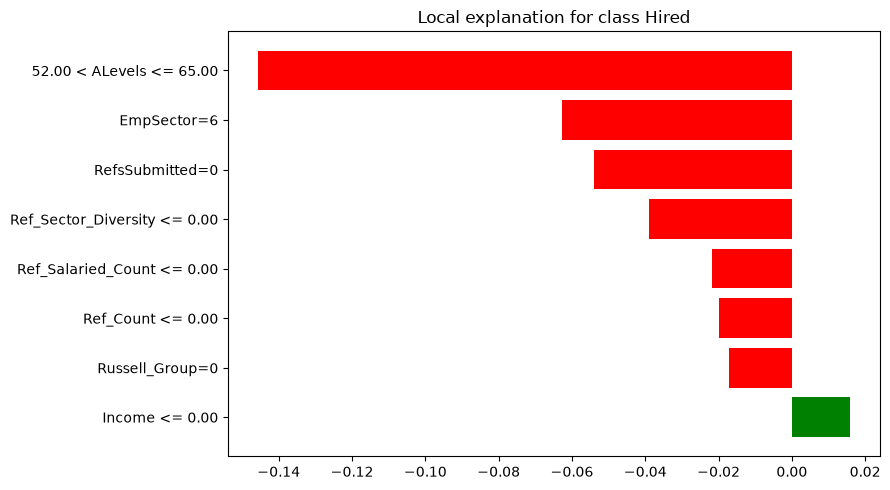


Saved LIME example plot

══════════════════════════════════════════════════════════════════════
SHAP vs LIME consistency check
══════════════════════════════════════════════════════════════════════

LIME aggregated top 10 (abs weight across 10 records):
  ALevels                    1.6599
  RefsSubmitted              0.6439
  52.00 < ALevels <= 65.00   0.2998
  EmpSector                  0.2766
  Ref_Count                  0.1886
  Ref_Sector_Diversity       0.1735
  Ref_Salaried_Count         0.1671
  0.00 < Ref_Count <= 3.00   0.1022
  Russell_Group              0.0791
  Income                     0.0606

SHAP top 10 (global):
  ALevels                    0.1300
  RefsSubmitted              0.0274
  EmpSector                  0.0256
  Ref_Sector_Diversity       0.0144
  Ref_Count                  0.0119
  Ref_Salaried_Count         0.0068
  Income                     0.0066
  Address                    0.0025
  Gender                     0.0022
  Russell_Group              0.0019

═

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import shap
import lime
import lime.lime_tabular
from scipy.stats import spearmanr

# ─────────────────────────────────────────────────────────────────────────────
# Load Part B results
# ─────────────────────────────────────────────────────────────────────────────
best_model = b['best_models'][b['best_name']]
X_train, X_test = b['X_train'], b['X_test']
y_train, y_test = b['y_train'], b['y_test']
print(f"Best model: {b['best_name']}")
print(f"Features: {list(X_train.columns)}")

feature_names = list(X_train.columns)

# ─────────────────────────────────────────────────────────────────────────────
# 1. SHAP — global explanations
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("SHAP ANALYSIS")
print("═" * 70)

# For AdaBoost (DecisionTree stumps), shap.TreeExplainer isn't supported;
# use KernelExplainer with a background sample (slower but model-agnostic).
# Sub-sample to keep compute tractable — SHAP kernel is O(n × background_size).
bg_size = 30          # background sample (matches report Section 4.1)
explain_size = 150    # evaluate SHAP on this many test rows (matches report Section 4.1)
rng = np.random.default_rng(42)

bg_idx = rng.choice(len(X_train), bg_size, replace=False)
background = X_train.iloc[bg_idx]

expl_idx = rng.choice(len(X_test), explain_size, replace=False)
X_explain = X_test.iloc[expl_idx]

print(f"Background sample: {bg_size}  |  Explain sample: {explain_size}")

# predict_proba returns a 2-col array (class 0, class 1) — take col 1 for "hired"
def f(X_arr):
    return best_model.predict_proba(X_arr)[:, 1]

print("Computing SHAP values via KernelExplainer (this can take a few minutes)...")
kernel_expl = shap.KernelExplainer(f, background)
shap_values = kernel_expl.shap_values(X_explain, nsamples=200)  # nsamples controls speed/quality (matches report)
print(f"SHAP values shape: {shap_values.shape}")

# Global importance — mean |SHAP|
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_importance = pd.DataFrame({
    'feature': feature_names,
    'mean_abs_shap': mean_abs_shap,
}).sort_values('mean_abs_shap', ascending=False)
print("\nSHAP global feature importance (top 10):")
print(shap_importance.head(10).to_string(index=False))

# Summary plot (bar form — most interpretable)
plt.figure(figsize=(9, 5))
shap.summary_plot(shap_values, X_explain, feature_names=feature_names,
                   plot_type='bar', show=False, max_display=12)
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_shap_bar.png', dpi=120, bbox_inches='tight')
plt.show()

# Beeswarm summary — shows direction of effect
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values, X_explain, feature_names=feature_names,
                   show=False, max_display=12)
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_shap_beeswarm.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved SHAP bar & beeswarm plots")

# SHAP dependence plots for the two most important features
print("\nGenerating SHAP dependence plots for top 2 features...")
top2 = shap_importance['feature'].head(2).tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feat in zip(axes, top2):
    feat_idx = feature_names.index(feat)
    shap.dependence_plot(feat_idx, shap_values, X_explain,
                          feature_names=feature_names,
                          ax=ax, show=False, interaction_index='auto')
    ax.set_title(f'SHAP dependence — {feat}')
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_shap_dependence.png', dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved SHAP dependence plots for {top2}")

# ─────────────────────────────────────────────────────────────────────────────
# 2. LIME — local explanations for 10 random test records
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("LIME ANALYSIS")
print("═" * 70)

# Identify which features should be treated as categorical (by position)
# — low-cardinality columns that were label-encoded
categorical_cols = ['Gender', 'Education', 'Employment', 'EmpSector',
                     'RefsSubmitted', 'Russell_Group']
cat_idx = [feature_names.index(c) for c in categorical_cols
            if c in feature_names]

lime_expl = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=feature_names,
    class_names=['Not Hired', 'Hired'],
    categorical_features=cat_idx,
    mode='classification',
    random_state=42,
)

# Pick 10 random test records
rng2 = np.random.default_rng(7)
lime_idx = rng2.choice(len(X_test), 10, replace=False)

lime_records = []
for i, idx in enumerate(lime_idx):
    x_row = X_test.iloc[idx].to_numpy()
    true_label = y_test.iloc[idx]
    pred_label = best_model.predict(x_row.reshape(1, -1))[0]
    pred_proba = best_model.predict_proba(x_row.reshape(1, -1))[0]

    exp = lime_expl.explain_instance(
        x_row, best_model.predict_proba,
        num_features=8, num_samples=1500,
    )

    # Extract explanation as list of (feature, weight)
    feat_contribs = exp.as_list()

    lime_records.append({
        'record_id': int(idx),
        'true_label': int(true_label),
        'pred_label': int(pred_label),
        'prob_hired': float(pred_proba[1]),
        'contribs': feat_contribs,
        'raw_values': X_test.iloc[idx].to_dict(),
    })

    print(f"\nRecord {idx}  (true={true_label}, pred={pred_label}, "
          f"P(hired)={pred_proba[1]:.3f}):")
    for feat, w in feat_contribs[:5]:
        direction = "↑ hired" if w > 0 else "↓ hired"
        print(f"  {feat:<40}  weight={w:+.3f}  [{direction}]")

# Save figure for a representative LIME instance (first one)
fig = lime_expl.explain_instance(
    X_test.iloc[lime_idx[0]].to_numpy(), best_model.predict_proba,
    num_features=8, num_samples=1500
).as_pyplot_figure()
fig.set_size_inches(9, 5)
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_lime_example.png', dpi=120, bbox_inches='tight')
plt.show()
print("\nSaved LIME example plot")

# ─────────────────────────────────────────────────────────────────────────────
# 3. Cross-check SHAP vs LIME rankings (consistency sanity check)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("SHAP vs LIME consistency check")
print("═" * 70)
# Aggregate LIME feature weights across the 10 records
lime_agg = {}
for rec in lime_records:
    for feat_str, w in rec['contribs']:
        # LIME strings are like "Age > 45.00" — pull the feature name prefix
        feat = next((f for f in feature_names if feat_str.startswith(f)), feat_str)
        lime_agg[feat] = lime_agg.get(feat, 0) + abs(w)
lime_rank = sorted(lime_agg.items(), key=lambda x: -x[1])[:10]
print("\nLIME aggregated top 10 (abs weight across 10 records):")
for feat, w in lime_rank:
    print(f"  {feat:<25}  {w:.4f}")

print("\nSHAP top 10 (global):")
for _, row in shap_importance.head(10).iterrows():
    print(f"  {row['feature']:<25}  {row['mean_abs_shap']:.4f}")

# ─────────────────────────────────────────────────────────────────────────────
# 4. Spearman rank correlation between SHAP and LIME global rankings
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("Spearman rank correlation: SHAP vs LIME (all features)")
print("═" * 70)

shap_dict = dict(zip(shap_importance['feature'], shap_importance['mean_abs_shap']))
shap_vec = np.array([shap_dict.get(f, 0.0) for f in feature_names])
lime_vec = np.array([lime_agg.get(f, 0.0) for f in feature_names])
rho, p_val = spearmanr(shap_vec, lime_vec)
print(f"Spearman rho       : {rho:.3f}")
print(f"p-value            : {p_val:.2e}")
print(f"# features compared: {len(feature_names)}")

# Make available downstream
c = {'shap_importance': shap_importance, 'shap_values': shap_values,
     'lime_records': lime_records, 'lime_agg': lime_agg,
     'spearman_rho': rho, 'spearman_p': p_val}

# Save Part C outputs


## 5. Part D — Fairness (aif360)

pip install 'aif360[AdversarialDebiasing]'


pip install 'aif360[AdversarialDebiasing]'


pip install 'aif360[Reductions]'


pip install 'aif360[Reductions]'


pip install 'aif360[inFairness]'


pip install 'aif360[Reductions]'


Gender encoding: {'Female': 0, 'Male': 1, 'Non-binary': 2, 'Trans': 3}

Test set for fairness analysis: 1760 records

══════════════════════════════════════════════════════════════════════
1. GROUP FAIRNESS METRICS
══════════════════════════════════════════════════════════════════════

→ Male vs Female  (n_priv=375, n_unpriv=403)
   GT Disparate Impact          : 0.789
   Model Disparate Impact       : 0.812
   Statistical Parity Diff      : -0.055
   Equal Opportunity Diff       : +0.022
   Average Odds Diff            : +0.010
   FPR priv / unpriv / diff     : 0.015 / 0.013 / -0.002
   TPR priv / unpriv            : 0.946 / 0.968

→ Male vs Trans  (n_priv=375, n_unpriv=497)
   GT Disparate Impact          : 0.788
   Model Disparate Impact       : 0.782
   Statistical Parity Diff      : -0.064
   Equal Opportunity Diff       : -0.006
   Average Odds Diff            : -0.005
   FPR priv / unpriv / diff     : 0.015 / 0.011 / -0.005
   TPR priv / unpriv            : 0.946 / 0.940

→ Male

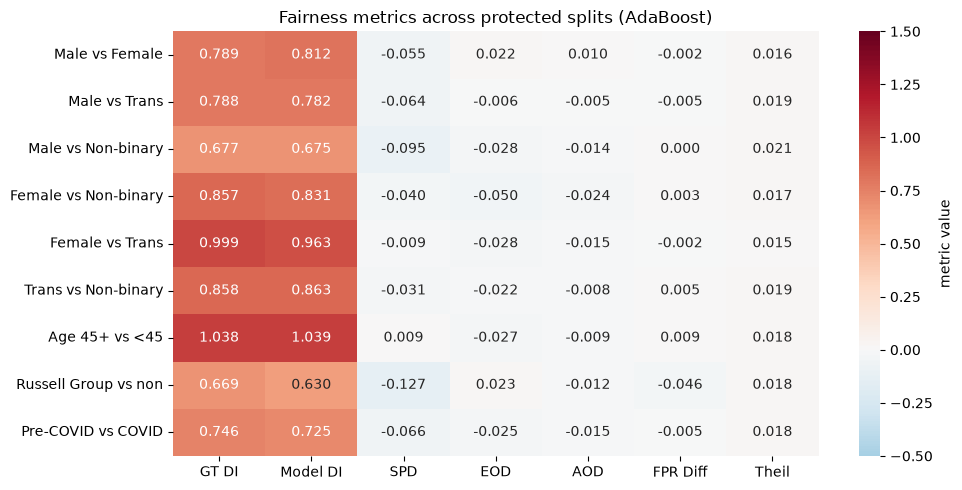

Saved fairness heatmap

══════════════════════════════════════════════════════════════════════
1b. EDUCATION FAIRNESS (pairwise)
══════════════════════════════════════════════════════════════════════

→ Arts vs Business  (n_priv=415, n_unpriv=466)
   GT DI    : 0.958
   Model DI : 0.965
   SPD      : -0.010
   EOD      : -0.014

→ Arts vs Law  (n_priv=415, n_unpriv=446)
   GT DI    : 0.733
   Model DI : 0.704
   SPD      : -0.085
   EOD      : -0.050

→ Arts vs STEM  (n_priv=415, n_unpriv=433)
   GT DI    : 0.682
   Model DI : 0.628
   SPD      : -0.107
   EOD      : -0.082

→ Business vs Law  (n_priv=466, n_unpriv=446)
   GT DI    : 0.765
   Model DI : 0.729
   SPD      : -0.075
   EOD      : -0.036

→ Business vs STEM  (n_priv=466, n_unpriv=433)
   GT DI    : 0.712
   Model DI : 0.651
   SPD      : -0.097
   EOD      : -0.068

→ Law vs STEM  (n_priv=446, n_unpriv=433)
   GT DI    : 0.930
   Model DI : 0.893
   SPD      : -0.022
   EOD      : -0.032

EDUCATION SUMMARY TABLE:
         

   Set all Gender → Female: 0.57% of predictions flip
   Set all Gender → Male: 0.57% of predictions flip
   Set all Gender → Non-binary: 0.74% of predictions flip
   Set all Gender → Trans: 0.74% of predictions flip



   Pairwise Male↔Female flip rate: 0.57% of predictions change

   ── Counterfactual on Russell Group ──
   Russell Group overall flip rate : 2.73%
   RG → non-RG flip rate           : 4.95%
   non-RG → RG flip rate           : 2.30%

══════════════════════════════════════════════════════════════════════
5. THEIL INDEX (generalised entropy of individual benefit)
══════════════════════════════════════════════════════════════════════
Theil index by protected split (lower = more individual equity):
   Male vs Female             Theil = 0.0156
   Male vs Trans              Theil = 0.0185
   Male vs Non-binary         Theil = 0.0209
   Female vs Non-binary       Theil = 0.0168
   Female vs Trans            Theil = 0.0146
   Trans vs Non-binary        Theil = 0.0193
   Age 45+ vs <45             Theil = 0.0176
   Russell Group vs non       Theil = 0.0176
   Pre-COVID vs COVID         Theil = 0.0176

══════════════════════════════════════════════════════════════════════
6. REWEIGHING MITIGAT


Reweighed model — test accuracy: 0.9773  |  F1 (hired=1): 0.9520
Baseline AdaBoost — test accuracy: 0.9761  |  F1 (hired=1): 0.9499

TABLE 10 — Disparate impact and equal opportunity, before vs after Reweighing:
                      DI base  DI RW  Delta DI  EOD base  EOD RW
Split                                                           
Male vs Female          0.812  0.801    -0.011     0.022   0.010
Male vs Trans           0.782  0.803     0.021    -0.006   0.011
Male vs Non-binary      0.675  0.687     0.012    -0.028  -0.009
Female vs Non-binary    0.831  0.858     0.027    -0.050  -0.019
Female vs Trans         0.963  1.003     0.040    -0.028   0.001
Trans vs Non-binary     0.863  0.855    -0.008    -0.022  -0.020
Age 45+ vs <45          1.039  1.009    -0.030    -0.027  -0.041
Russell Group vs non    0.630  0.606    -0.024     0.023  -0.008
Pre-COVID vs COVID      0.725  0.700    -0.025    -0.025  -0.022


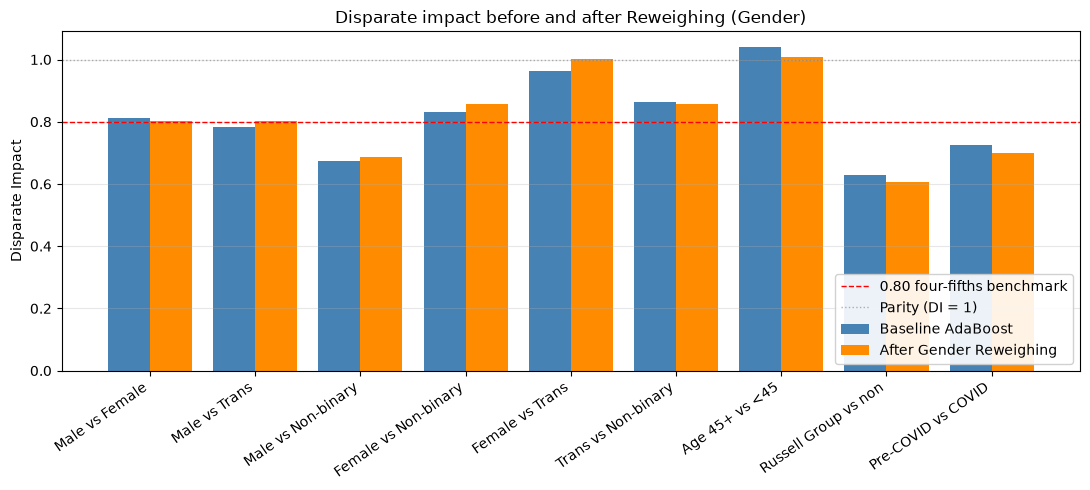


Saved → docs/figures/fig_reweighing_comparison.png


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric, BinaryLabelDatasetMetric
from aif360.algorithms.preprocessing import Reweighing
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score

# ─────────────────────────────────────────────────────────────────────────────
# Load pipeline outputs
# ─────────────────────────────────────────────────────────────────────────────
df_cls = pp['df_cls']
gender_map = pp['gender_map']  # {'Female': 0, 'Male': 1, 'Non-binary': 2, 'Trans': 3}
print("Gender encoding:", gender_map)

best_model = b['best_models'][b['best_name']]
X_test, y_test = b['X_test'], b['y_test']
y_pred_best = b['y_pred_best']

# Join test predictions back into a single fairness-ready frame
df_test = X_test.copy().reset_index(drop=True)
df_test['Hired_true'] = y_test.reset_index(drop=True).values
df_test['Hired_pred'] = y_pred_best
print(f"\nTest set for fairness analysis: {len(df_test)} records")

# Raw gender/year/age values from the full dataset (decoded) for reporting
df_raw = pp['df_raw']
df_raw_test = df_raw.iloc[y_test.index].reset_index(drop=True)
df_test['Gender_name'] = df_raw_test['Gender'].values
df_test['Year_val'] = df_raw_test['Year'].values
df_test['Age_val'] = df_raw_test['Age'].values
df_test['Education_name'] = df_raw_test['Education'].values  # for education fairness check

# ─────────────────────────────────────────────────────────────────────────────
# Helper — compute group-fairness metrics for a given privileged split
# ─────────────────────────────────────────────────────────────────────────────
def compute_group_metrics(df, protected_col, privileged_val, label_col, pred_col):
    """
    Wraps df into aif360 BinaryLabelDatasets and returns a dict of metrics.

    • label_col  = ground-truth column   → used by dataset
    • pred_col   = predicted labels      → used by classified_dataset
    privileged_val is the value of protected_col that flags the privileged group.
    """
    # aif360 requires the protected column to be binary 0/1 where 1 = privileged.
    work = df.copy()
    work['_P_'] = (work[protected_col] == privileged_val).astype(int)

    needed = ['_P_', label_col, pred_col]
    gt = BinaryLabelDataset(
        favorable_label=1, unfavorable_label=0,
        df=work[needed + []].rename(columns={label_col: 'label'}).drop(columns=[pred_col]),
        label_names=['label'], protected_attribute_names=['_P_'])
    pr = BinaryLabelDataset(
        favorable_label=1, unfavorable_label=0,
        df=work[needed + []].rename(columns={pred_col: 'label'}).drop(columns=[label_col]),
        label_names=['label'], protected_attribute_names=['_P_'])

    cm = ClassificationMetric(
        gt, pr,
        unprivileged_groups=[{'_P_': 0}],
        privileged_groups=[{'_P_': 1}],
    )

    # Dataset bias — selection rates in ground truth only
    bm = BinaryLabelDatasetMetric(
        gt, unprivileged_groups=[{'_P_': 0}], privileged_groups=[{'_P_': 1}])

    return {
        # Ground-truth (dataset) bias
        'GT Disparate Impact': bm.disparate_impact(),
        'GT Statistical Parity Diff': bm.statistical_parity_difference(),
        # Model bias (on predictions)
        'MODEL Disparate Impact': cm.disparate_impact(),
        'MODEL Statistical Parity Diff': cm.statistical_parity_difference(),
        'MODEL Equal Opportunity Diff': cm.equal_opportunity_difference(),
        'MODEL Average Odds Diff': cm.average_odds_difference(),
        'MODEL FPR (priv)': cm.false_positive_rate(privileged=True),
        'MODEL FPR (unpriv)': cm.false_positive_rate(privileged=False),
        'MODEL FPR Diff': cm.false_positive_rate_difference(),
        'MODEL TPR (priv)': cm.true_positive_rate(privileged=True),
        'MODEL TPR (unpriv)': cm.true_positive_rate(privileged=False),
        'MODEL Theil Index': cm.theil_index(),
        'n_priv': int((work['_P_'] == 1).sum()),
        'n_unpriv': int((work['_P_'] == 0).sum()),
    }

# ─────────────────────────────────────────────────────────────────────────────
# 1. GROUP FAIRNESS — all protected splits
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("1. GROUP FAIRNESS METRICS")
print("═" * 70)

# Pre-compute binary protected columns for the extra attributes
df_test['AgeBand'] = (df_test['Age_val'] >= 45).astype(int)   # 1 = 45+ privileged
df_test['COVID']   = df_test['Year_val'].between(2020, 2021).astype(int)  # 1 = COVID-era (unpriv)
df_test['PreCOVID'] = 1 - df_test['COVID']  # make 1 = privileged (pre-COVID)

# List of (label, column, privileged_value, unprivileged_label) to evaluate.
# All 6 gender pairs are included so the audit covers Female/Trans/Non-binary
# pairwise as well as Male-vs-others (matches Table 7 in the report).
group_splits = [
    ('Male vs Female',         'Gender', gender_map['Male'],   'Female'),
    ('Male vs Trans',          'Gender', gender_map['Male'],   'Trans'),
    ('Male vs Non-binary',     'Gender', gender_map['Male'],   'Non-binary'),
    ('Female vs Non-binary',   'Gender', gender_map['Female'], 'Non-binary'),
    ('Female vs Trans',        'Gender', gender_map['Female'], 'Trans'),
    ('Trans vs Non-binary',    'Gender', gender_map['Trans'],  'Non-binary'),
    ('Age 45+ vs <45',         'AgeBand', 1, '<45'),
    ('Russell Group vs non',   'Russell_Group', 1, 'non-RG'),
    ('Pre-COVID vs COVID',     'PreCOVID', 1, 'COVID-era'),
]

group_results = {}
for name, col, priv, unpriv_label in group_splits:
    # For Gender splits we need to filter to just priv + one unpriv category
    if col == 'Gender':
        unpriv_val = gender_map[unpriv_label]
        df_sub = df_test[df_test[col].isin([priv, unpriv_val])].copy()
    else:
        df_sub = df_test.copy()

    res = compute_group_metrics(df_sub, col, priv, 'Hired_true', 'Hired_pred')
    group_results[name] = res

    print(f"\n→ {name}  (n_priv={res['n_priv']}, n_unpriv={res['n_unpriv']})")
    print(f"   GT Disparate Impact          : {res['GT Disparate Impact']:.3f}")
    print(f"   Model Disparate Impact       : {res['MODEL Disparate Impact']:.3f}")
    print(f"   Statistical Parity Diff      : {res['MODEL Statistical Parity Diff']:+.3f}")
    print(f"   Equal Opportunity Diff       : {res['MODEL Equal Opportunity Diff']:+.3f}")
    print(f"   Average Odds Diff            : {res['MODEL Average Odds Diff']:+.3f}")
    print(f"   FPR priv / unpriv / diff     : {res['MODEL FPR (priv)']:.3f} / "
          f"{res['MODEL FPR (unpriv)']:.3f} / {res['MODEL FPR Diff']:+.3f}")
    print(f"   TPR priv / unpriv            : {res['MODEL TPR (priv)']:.3f} / "
          f"{res['MODEL TPR (unpriv)']:.3f}")

# Collect as a single dataframe for the report
group_df = pd.DataFrame(group_results).T[['GT Disparate Impact',
    'MODEL Disparate Impact', 'MODEL Statistical Parity Diff',
    'MODEL Equal Opportunity Diff', 'MODEL Average Odds Diff',
    'MODEL FPR Diff', 'MODEL Theil Index']]
group_df.columns = ['GT DI', 'Model DI', 'SPD', 'EOD', 'AOD', 'FPR Diff', 'Theil']
print("\n\nSUMMARY TABLE:")
print(group_df.round(3).to_string())

# Plot summary heatmap
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(group_df.round(3), annot=True, fmt='.3f', cmap='RdBu_r',
             center=0, cbar_kws={'label': 'metric value'}, ax=ax,
             vmin=-0.5, vmax=1.5)
ax.set_title('Fairness metrics across protected splits (AdaBoost)')
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_fairness_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved fairness heatmap")


# ─────────────────────────────────────────────────────────────────────────────
# 1b. EDUCATION ATTRIBUTE FAIRNESS — pairwise (matches Table 8 in report)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("1b. EDUCATION FAIRNESS (pairwise)")
print("═" * 70)

edu_pairs = [('Arts', 'Business'), ('Arts', 'Law'), ('Arts', 'STEM'),
             ('Business', 'Law'),  ('Business', 'STEM'), ('Law', 'STEM')]
education_results = {}
for a, b_ in edu_pairs:
    df_sub = df_test[df_test['Education_name'].isin([a, b_])].copy()
    # Privileged = higher ground-truth hire rate of the pair
    rates = df_sub.groupby('Education_name')['Hired_true'].mean()
    priv_name = a if rates[a] >= rates[b_] else b_
    unpriv_name = b_ if priv_name == a else a
    res = compute_group_metrics(df_sub, 'Education_name', priv_name,
                                 'Hired_true', 'Hired_pred')
    label = f"{priv_name} vs {unpriv_name}"
    education_results[label] = res
    print(f"\n→ {label}  (n_priv={res['n_priv']}, n_unpriv={res['n_unpriv']})")
    print(f"   GT DI    : {res['GT Disparate Impact']:.3f}")
    print(f"   Model DI : {res['MODEL Disparate Impact']:.3f}")
    print(f"   SPD      : {res['MODEL Statistical Parity Diff']:+.3f}")
    print(f"   EOD      : {res['MODEL Equal Opportunity Diff']:+.3f}")

edu_df = pd.DataFrame(education_results).T[['GT Disparate Impact',
    'MODEL Disparate Impact', 'MODEL Statistical Parity Diff',
    'MODEL Equal Opportunity Diff']]
edu_df.columns = ['GT DI', 'Model DI', 'SPD', 'EOD']
print("\nEDUCATION SUMMARY TABLE:")
print(edu_df.round(3).to_string())

# ─────────────────────────────────────────────────────────────────────────────
# 2. INTERSECTIONAL — Gender × Russell Group
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("2. INTERSECTIONAL ANALYSIS")
print("═" * 70)

intersec = df_test.groupby(['Gender_name', 'Russell_Group']).agg(
    n=('Hired_true', 'count'),
    true_hire_rate=('Hired_true', 'mean'),
    pred_hire_rate=('Hired_pred', 'mean'),
).round(3)
print(intersec)

# ─────────────────────────────────────────────────────────────────────────────
# 3. INDIVIDUAL FAIRNESS — Consistency via k-NN
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("3. INDIVIDUAL FAIRNESS")
print("═" * 70)

# Consistency (Zemel et al. 2013): for each test point, compare its prediction
# to the average prediction of its k-nearest neighbours (in feature space
# excluding the label and protected attrs).
# Value close to 1 = consistent (similar cases get similar predictions).

# Exclude protected attrs + derived binary flags from the neighbour space so
# that "similarity" is judged on legitimate job-relevant factors only.
protected_cols = ['Gender', 'AgeBand', 'PreCOVID', 'COVID', 'Gender_name',
                   'Year_val', 'Age_val', 'Education_name', 'Hired_true', 'Hired_pred']
feat_cols = [c for c in df_test.columns if c not in protected_cols]

X_for_knn = df_test[feat_cols].to_numpy()
# Normalise continuous columns so they don't dominate Euclidean distance
from sklearn.preprocessing import StandardScaler
X_norm = StandardScaler().fit_transform(X_for_knn)

for k_knn in [5, 10]:
    nn = NearestNeighbors(n_neighbors=k_knn + 1)  # +1 because self is neighbour-0
    nn.fit(X_norm)
    _, idx = nn.kneighbors(X_norm)
    # Drop self-match
    idx = idx[:, 1:]
    neighbour_preds = df_test['Hired_pred'].to_numpy()[idx].mean(axis=1)
    consistency = 1 - np.mean(np.abs(df_test['Hired_pred'].to_numpy() - neighbour_preds))
    print(f"Consistency score (k={k_knn}): {consistency:.4f}")

# ─── Sensitivity check: Gower distance on a 500-row sample ──────────────────
# Gower (1971) handles continuous and categorical variables natively, unlike
# Euclidean which treats label-encoded categoricals as ordinals. If results
# agree with Euclidean, the consistency conclusion is robust to distance choice.
print("\nSensitivity check: Gower distance (handles categoricals natively)")

cat_set = {'Gender', 'Education', 'Employment', 'EmpSector', 'Address',
           'RefsSubmitted', 'Russell_Group'}
cat_idx_g = [i for i, c_ in enumerate(feat_cols) if c_ in cat_set]

def gower_distance_matrix(X, cat_idx_set):
    n, p = X.shape
    D = np.zeros((n, n))
    cat_idx_set = set(cat_idx_set)
    for j in range(p):
        col = X[:, j].astype(float)
        if j in cat_idx_set:
            mat = (col[:, None] != col[None, :]).astype(float)
        else:
            rng_ = col.max() - col.min()
            if rng_ == 0:
                mat = np.zeros((n, n))
            else:
                mat = np.abs(col[:, None] - col[None, :]) / rng_
        D += mat
    return D / p

gower_sample_n = 500
rng_g = np.random.default_rng(42)
sample_pos = rng_g.choice(len(df_test), size=min(gower_sample_n, len(df_test)),
                           replace=False)
X_g = df_test[feat_cols].iloc[sample_pos].to_numpy()
D_g = gower_distance_matrix(X_g, cat_idx_g)
preds_g = df_test['Hired_pred'].to_numpy()[sample_pos]

for k_knn in [5, 10]:
    # For each row, take the k smallest distances excluding self
    neigh_idx = np.argsort(D_g, axis=1)[:, 1:k_knn + 1]
    neigh_pred_mean = preds_g[neigh_idx].mean(axis=1)
    cons_g = 1 - np.mean(np.abs(preds_g - neigh_pred_mean))
    print(f"Gower consistency (k={k_knn}, n={gower_sample_n}): {cons_g:.4f}")

# ─────────────────────────────────────────────────────────────────────────────
# 4. COUNTERFACTUAL FAIRNESS — flip Gender, see how often prediction changes
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("4. COUNTERFACTUAL FAIRNESS (Gender flip)")
print("═" * 70)

flip_results = {}
original_preds = best_model.predict(X_test.to_numpy())

for flip_to_name, flip_to_val in gender_map.items():
    X_flipped = X_test.copy()
    X_flipped['Gender'] = flip_to_val
    flipped_preds = best_model.predict(X_flipped.to_numpy())
    flip_rate = (original_preds != flipped_preds).mean()
    flip_results[f'Set all → {flip_to_name}'] = flip_rate
    print(f"   Set all Gender → {flip_to_name}: {flip_rate*100:.2f}% of predictions flip")

# Also: the pairwise flip — flip each candidate to the *opposite* dominant group
# (for Males: flip to Female; for non-Males: flip to Male) as a symmetric test
pairwise_flip_count = 0
for i in range(len(X_test)):
    x_orig = X_test.iloc[i:i+1].copy()
    target_gender = gender_map['Female'] if x_orig['Gender'].iloc[0] == gender_map['Male'] else gender_map['Male']
    x_cf = x_orig.copy()
    x_cf['Gender'] = target_gender
    p_orig = best_model.predict(x_orig.to_numpy())[0]
    p_cf = best_model.predict(x_cf.to_numpy())[0]
    if p_orig != p_cf:
        pairwise_flip_count += 1
pairwise_rate = pairwise_flip_count / len(X_test)
print(f"\n   Pairwise Male↔Female flip rate: {pairwise_rate*100:.2f}% of predictions change")

# ─── Russell Group counterfactual (where the largest group disparity lives) ──
print("\n   ── Counterfactual on Russell Group ──")
X_rg_flip = X_test.copy()
X_rg_flip['Russell_Group'] = 1 - X_rg_flip['Russell_Group']
flipped_rg = best_model.predict(X_rg_flip.to_numpy())
rg_overall = (original_preds != flipped_rg).mean()

mask_rg   = (X_test['Russell_Group'] == 1).to_numpy()
mask_norg = (X_test['Russell_Group'] == 0).to_numpy()
rg_to_norg = (original_preds[mask_rg]   != flipped_rg[mask_rg]).mean()   if mask_rg.any() else 0.0
norg_to_rg = (original_preds[mask_norg] != flipped_rg[mask_norg]).mean() if mask_norg.any() else 0.0

print(f"   Russell Group overall flip rate : {rg_overall*100:.2f}%")
print(f"   RG → non-RG flip rate           : {rg_to_norg*100:.2f}%")
print(f"   non-RG → RG flip rate           : {norg_to_rg*100:.2f}%")
flip_results['Russell Group overall'] = rg_overall
flip_results['RG → non-RG'] = rg_to_norg
flip_results['non-RG → RG'] = norg_to_rg

# ─────────────────────────────────────────────────────────────────────────────
# 5. THEIL INDEX — already in classifier metric; compute directly for gender too
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("5. THEIL INDEX (generalised entropy of individual benefit)")
print("═" * 70)
# Theil in aif360 is measured on a 'benefit' vector b_i = y_pred_i - y_true_i + 1
# (0 if FN, 1 if correct, 2 if FP) so equal treatment → low Theil.
# The value was already computed per split in group_df above; extract the one
# we treat as primary (Male vs Trans gender disparity).
print("Theil index by protected split (lower = more individual equity):")
for name, res in group_results.items():
    print(f"   {name:<25}  Theil = {res['MODEL Theil Index']:.4f}")


# ─────────────────────────────────────────────────────────────────────────────
# 6. MITIGATION — aif360 Reweighing on Gender (Section 5.6 of report, Table 10)
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("6. REWEIGHING MITIGATION (Gender as protected, Male = privileged)")
print("═" * 70)

# Build a training BinaryLabelDataset with Gender binarised: 1 = Male (priv), 0 = others
train_df = X_train.copy()
train_df['label'] = y_train.values
train_df['_P_'] = (train_df['Gender'] == gender_map['Male']).astype(int)

# aif360 wants only label + protected attribute as label/protected names; other
# columns are kept as features. We pass the full frame but flag only label/_P_.
keep_cols = [c for c in train_df.columns if c != 'Gender']  # drop raw Gender (replaced by _P_)
train_bld = BinaryLabelDataset(
    favorable_label=1, unfavorable_label=0,
    df=train_df[keep_cols],
    label_names=['label'],
    protected_attribute_names=['_P_'],
)

RW = Reweighing(unprivileged_groups=[{'_P_': 0}], privileged_groups=[{'_P_': 1}])
train_rw = RW.fit_transform(train_bld)
weights = train_rw.instance_weights
print(f"Instance-weight summary (n={len(weights)}):")
print(f"  min={weights.min():.3f}, mean={weights.mean():.3f}, max={weights.max():.3f}")

# Retrain AdaBoost with the same hyperparameters as the chosen baseline
ada_baseline = best_models['AdaBoost']
ada_rw_clf = AdaBoostClassifier(
    n_estimators=ada_baseline.n_estimators,
    learning_rate=ada_baseline.learning_rate,
    random_state=42,
)
ada_rw_clf.fit(X_train, y_train, sample_weight=weights)
y_pred_rw = ada_rw_clf.predict(X_test)
acc_rw = accuracy_score(y_test, y_pred_rw)
f1_rw  = f1_score(y_test, y_pred_rw, pos_label=1)
print(f"\nReweighed model — test accuracy: {acc_rw:.4f}  |  F1 (hired=1): {f1_rw:.4f}")
print(f"Baseline AdaBoost — test accuracy: "
      f"{accuracy_score(y_test, y_pred_best):.4f}  |  "
      f"F1 (hired=1): {f1_score(y_test, y_pred_best, pos_label=1):.4f}")

# Compute the same group fairness metrics on the reweighed predictions
df_test_rw = df_test.copy()
df_test_rw['Hired_pred'] = y_pred_rw
group_results_rw = {}
for name, col, priv, unpriv_label in group_splits:
    if col == 'Gender':
        unpriv_val = gender_map[unpriv_label]
        df_sub = df_test_rw[df_test_rw[col].isin([priv, unpriv_val])].copy()
    else:
        df_sub = df_test_rw.copy()
    res = compute_group_metrics(df_sub, col, priv, 'Hired_true', 'Hired_pred')
    group_results_rw[name] = res

# Build comparison table (DI base/RW + EOD base/RW) — populates Table 10
splits = list(group_results.keys())
comp_rows = []
for s in splits:
    di_b = group_results[s]['MODEL Disparate Impact']
    di_r = group_results_rw[s]['MODEL Disparate Impact']
    eo_b = group_results[s]['MODEL Equal Opportunity Diff']
    eo_r = group_results_rw[s]['MODEL Equal Opportunity Diff']
    comp_rows.append({'Split': s, 'DI base': di_b, 'DI RW': di_r,
                      'Delta DI': di_r - di_b,
                      'EOD base': eo_b, 'EOD RW': eo_r})
comp_df = pd.DataFrame(comp_rows).set_index('Split').round(3)
print("\nTABLE 10 — Disparate impact and equal opportunity, before vs after Reweighing:")
print(comp_df.to_string())

# Plot DI before/after across splits (Figure 10)
fig, ax = plt.subplots(figsize=(11, 5))
xpos = np.arange(len(splits))
di_base = [group_results[s]['MODEL Disparate Impact']    for s in splits]
di_rw   = [group_results_rw[s]['MODEL Disparate Impact'] for s in splits]
ax.bar(xpos - 0.2, di_base, 0.4, label='Baseline AdaBoost',  color='steelblue')
ax.bar(xpos + 0.2, di_rw,   0.4, label='After Gender Reweighing', color='darkorange')
ax.axhline(0.80, color='red', linestyle='--', linewidth=1, label='0.80 four-fifths benchmark')
ax.axhline(1.00, color='grey', linestyle=':', linewidth=1, alpha=0.6, label='Parity (DI = 1)')
ax.set_xticks(xpos)
ax.set_xticklabels(splits, rotation=35, ha='right')
ax.set_ylabel('Disparate Impact')
ax.set_title('Disparate impact before and after Reweighing (Gender)')
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(FIG_DIR + '/fig_reweighing_comparison.png', dpi=120, bbox_inches='tight')
plt.show()
print("\nSaved → docs/figures/fig_reweighing_comparison.png")

# ─────────────────────────────────────────────────────────────────────────────
# Save everything
# ─────────────────────────────────────────────────────────────────────────────
